In [4]:
import sys
from pathlib import Path

# Add project root to sys.path
ROOT_DIR = Path.cwd().parent
if str(ROOT_DIR) not in sys.path:
    sys.path.append(str(ROOT_DIR))

import torch
import matplotlib.pyplot as plt
from src.config import Config
from src.utils.seed import set_seed
from src.utils.io_helpers import save_checkpoint, save_json
from src.dataset import get_dataloaders
from src.models.mlp_classifier import MLPClassifier, FrozenLatentDecoder
from src.trainers.train_mlp import train_mlp_classifier, train_frozen_latent_decoder
from src.evaluation.mlp_limitations import run_mlp_limitation_experiments

In [5]:
set_seed(Config.SEED)
Config.ensure_dirs()
train_loader, val_loader, test_loader = get_dataloaders()

In [6]:
mlp_classifier = MLPClassifier(
    input_dim=Config.INPUT_DIM,
    hidden_dim=Config.MLP_HIDDEN_DIMS[0],
    latent_dim=Config.MLP_LATENT_DIM,
    num_classes=Config.NUM_CLASSES,
)

clf_results = train_mlp_classifier(
    model=mlp_classifier,
    train_loader=train_loader,
    val_loader=val_loader,
    test_loader=test_loader,
    epochs=Config.MLP_EPOCHS,
    lr=Config.MLP_LR,
    device=Config.DEVICE,
)

save_checkpoint(
    mlp_classifier,
    Config.CHECKPOINT_DIR / "mlp_classifier.pth",
    extra_info={"test_acc": clf_results["test_acc"]},
)

[MLP Classifier] Epoch 01/20 | Train Loss: 0.6085 | Val Loss: 0.4686 | Val Acc: 83.49% | Time: 19.83s
[MLP Classifier] Epoch 02/20 | Train Loss: 0.4096 | Val Loss: 0.4030 | Val Acc: 85.29% | Time: 18.61s
[MLP Classifier] Epoch 03/20 | Train Loss: 0.3624 | Val Loss: 0.3694 | Val Acc: 86.77% | Time: 18.37s
[MLP Classifier] Epoch 04/20 | Train Loss: 0.3339 | Val Loss: 0.3569 | Val Acc: 87.11% | Time: 17.39s
[MLP Classifier] Epoch 05/20 | Train Loss: 0.3111 | Val Loss: 0.3334 | Val Acc: 87.73% | Time: 18.43s
[MLP Classifier] Epoch 06/20 | Train Loss: 0.2974 | Val Loss: 0.3392 | Val Acc: 87.61% | Time: 18.30s
[MLP Classifier] Epoch 07/20 | Train Loss: 0.2856 | Val Loss: 0.3244 | Val Acc: 88.16% | Time: 20.12s
[MLP Classifier] Epoch 08/20 | Train Loss: 0.2716 | Val Loss: 0.3385 | Val Acc: 87.97% | Time: 19.26s
[MLP Classifier] Epoch 09/20 | Train Loss: 0.2630 | Val Loss: 0.3288 | Val Acc: 88.01% | Time: 20.02s
[MLP Classifier] Epoch 10/20 | Train Loss: 0.2533 | Val Loss: 0.3206 | Val Acc: 88

In [7]:
frozen_decoder = FrozenLatentDecoder(
    latent_dim=Config.MLP_LATENT_DIM,
    hidden_dim=Config.MLP_HIDDEN_DIMS[0],
    output_dim=Config.INPUT_DIM,
)

decoder_history = train_frozen_latent_decoder(
    classifier=mlp_classifier,
    decoder=frozen_decoder,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=Config.FROZEN_DECODER_EPOCHS,
    lr=Config.FROZEN_DECODER_LR,
    device=Config.DEVICE,
)

save_checkpoint(frozen_decoder, Config.CHECKPOINT_DIR / "mlp_frozen_decoder.pth")

[Frozen MLP Decoder] Epoch 01/25 | Train MSE: 0.035646 | Val MSE: 0.025996
[Frozen MLP Decoder] Epoch 05/25 | Train MSE: 0.019868 | Val MSE: 0.019782
[Frozen MLP Decoder] Epoch 10/25 | Train MSE: 0.018101 | Val MSE: 0.018468
[Frozen MLP Decoder] Epoch 15/25 | Train MSE: 0.017363 | Val MSE: 0.017845
[Frozen MLP Decoder] Epoch 20/25 | Train MSE: 0.016947 | Val MSE: 0.017457
[Frozen MLP Decoder] Epoch 25/25 | Train MSE: 0.016633 | Val MSE: 0.017281


In [8]:
exp_results = run_mlp_limitation_experiments(
    classifier=mlp_classifier,
    frozen_decoder=frozen_decoder,
    test_loader=test_loader,
    device=Config.DEVICE,
    num_classes=Config.NUM_CLASSES,
    num_vis_samples=8,
)

print("Frozen MLP Decoder Test Metrics:", exp_results["frozen_decoder_metrics"])
print("MLP Latent Space Stats:", exp_results["latent_stats"])

# Save numerical metrics & visual tensors for Figure 3 later
save_json(
    {
        "classifier_test_acc": round(clf_results["test_acc"], 4),
        "frozen_decoder_metrics": exp_results["frozen_decoder_metrics"],
        "latent_stats": exp_results["latent_stats"],
    },
    Config.METRICS_DIR / "mlp_limitations_metrics.json",
)
torch.save(exp_results["visuals"], Config.METRICS_DIR / "mlp_limitations_visuals.pt")

Frozen MLP Decoder Test Metrics: {'mse': 0.017125, 'psnr': 17.6636, 'ssim': 0.7124}
MLP Latent Space Stats: {'mu_mean': 1.5177, 'sigma_mean': 1.8867, 'sparsity_zero_ratio': 0.561}


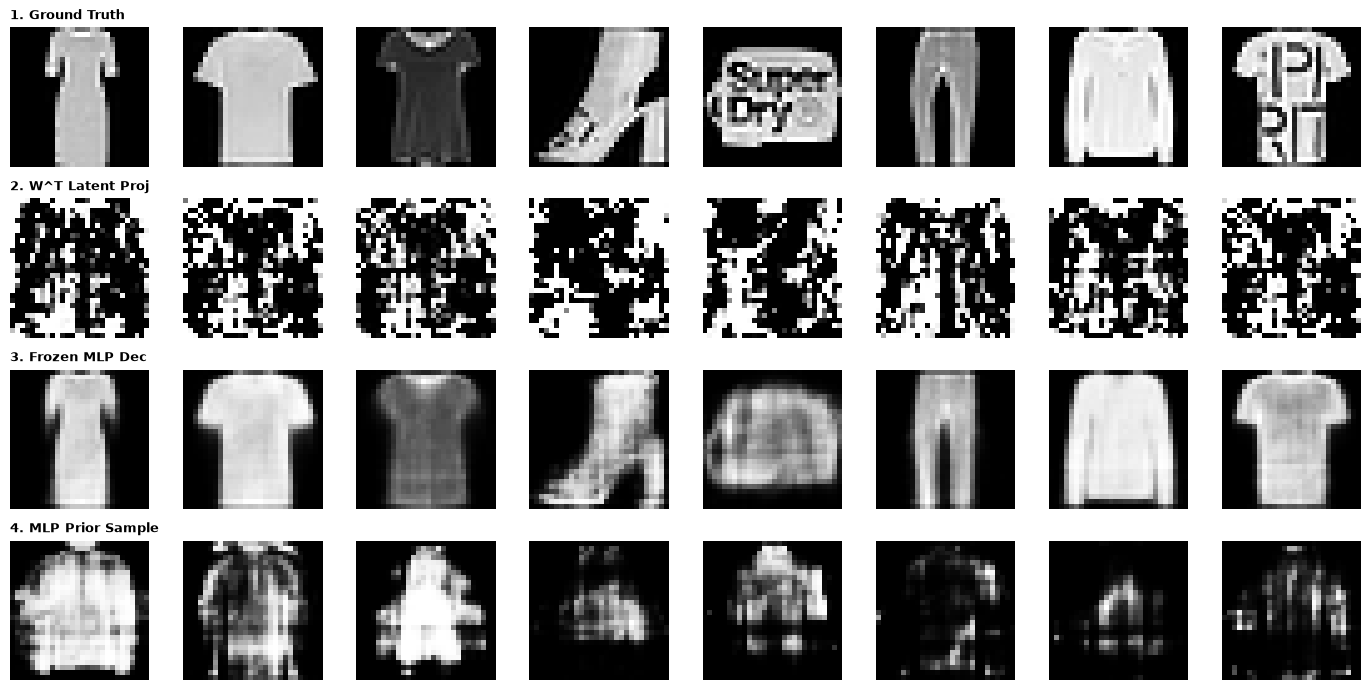

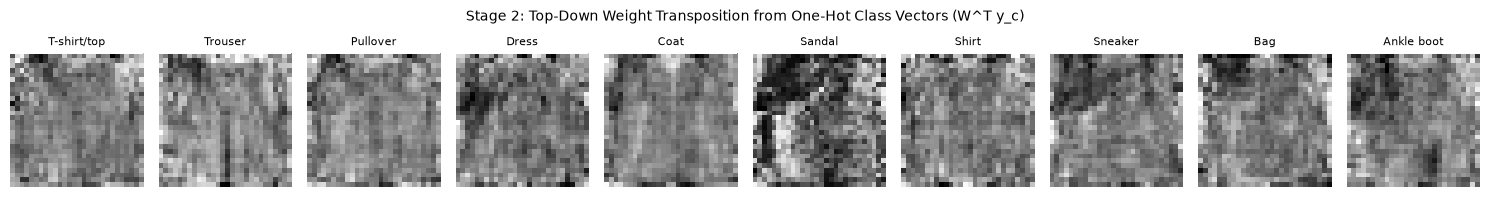

In [9]:
vis = exp_results["visuals"]

fig, axes = plt.subplots(4, 8, figsize=(14, 7))
row_titles = [
    "1. Ground Truth",
    "2. W^T Latent Proj",
    "3. Frozen MLP Dec",
    "4. MLP Prior Sample",
]
rows = [
    vis["ground_truth"],
    vis["latent_transpose"],
    vis["frozen_decoder_recon"],
    vis["mlp_prior_samples"],
]

for r_idx, (title, imgs) in enumerate(zip(row_titles, rows)):
    for c_idx in range(8):
        axes[r_idx, c_idx].imshow(imgs[c_idx].squeeze(), cmap="gray")
        axes[r_idx, c_idx].axis("off")
        if c_idx == 0:
            axes[r_idx, c_idx].set_title(title, fontsize=9, loc="left", fontweight="bold")

plt.tight_layout()
plt.show()

# Also inspect Stage 2: Class One-Hot W^T back-projection (10 classes)
fig2, axes2 = plt.subplots(1, 10, figsize=(15, 2))
for c in range(10):
    axes2[c].imshow(vis["class_transpose"][c].squeeze(), cmap="gray")
    axes2[c].set_title(Config.CLASS_NAMES[c], fontsize=8)
    axes2[c].axis("off")
plt.suptitle("Stage 2: Top-Down Weight Transposition from One-Hot Class Vectors (W^T y_c)", fontsize=10)
plt.tight_layout()
plt.show()